# P01: explore the WikiArt subset

We downloaded 3,000 paintings (5 genres x 600) with `make_wikiart_subset.py`. Before training anything, we look at
what the data really is. Every figure about the images that is quoted in ADR 0002 and ADR 0003 is computed here.

Run it with the project's `.venv` as kernel. The data path below is relative to this notebook's folder (`vision/`).

In [3]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

DATA_DIR = Path("../../../data/wikiart_genre5")

meta = pd.read_csv(DATA_DIR / "metadata.csv")
info = json.loads((DATA_DIR / "subset_info.json").read_text())
genres = sorted(meta["label"].unique())

print("built with:", info["command"])
meta.head()

built with: python make_wikiart_subset.py --label genre --classes portrait landscape cityscape still_life religious_painting --per-class 600 --size 224 --out data/wikiart_genre5


,path,label,label_idx,id,style,genre,artist,shard,row,orig_width,orig_height
0,cityscape/s51_r0001.jpg,cityscape,0,s51_r0001,Romanticism,cityscape,Unknown Artist,51,1,1382,1930
1,cityscape/s51_r0005.jpg,cityscape,0,s51_r0005,Impressionism,cityscape,Unknown Artist,51,5,2000,1382
2,cityscape/s51_r0008.jpg,cityscape,0,s51_r0008,Realism,cityscape,vasily-vereshchagin,51,8,1947,1382
3,cityscape/s51_r0009.jpg,cityscape,0,s51_r0009,Impressionism,cityscape,gustave-caillebotte,51,9,1382,1985
4,cityscape/s51_r0010.jpg,cityscape,0,s51_r0010,Post_Impressionism,cityscape,Unknown Artist,51,10,1827,1382


## 1. Is the download complete and consistent?

`metadata.csv` has one row per image. We check that it matches the files on disk.

In [4]:
files_on_disk = {p.relative_to(DATA_DIR).as_posix() for p in DATA_DIR.glob("*/*.jpg")}

print("rows in metadata.csv:", len(meta))
print("jpg files on disk:", len(files_on_disk))
print("in metadata.csv but missing on disk:", len(set(meta["path"]) - files_on_disk))
print("on disk but not in metadata.csv:", len(files_on_disk - set(meta["path"])))
print("label different from the genre column:", (meta["label"] != meta["genre"]).sum())
print("label_idx different from the sorted genre order:", (meta["label"].map(genres.index) != meta["label_idx"]).sum())
print("duplicated ids:", meta["id"].duplicated().sum())

rows in metadata.csv: 3000
jpg files on disk: 3000
in metadata.csv but missing on disk: 0
on disk but not in metadata.csv: 0
label different from the genre column: 0
label_idx different from the sorted genre order: 0
duplicated ids: 0


## 2. Images per genre

In [5]:
meta["label"].value_counts().sort_index()

label
cityscape             600
landscape             600
portrait              600
religious_painting    600
still_life            600
Name: count, dtype: int64

## 3. Who painted them?

Each painting has an `artist`. When WikiArt does not know the painter, the label is `Unknown Artist`: a catch-all
for many different people, so we cannot tell whether two such paintings share a painter.

In [6]:
meta["known"] = meta["artist"] != "Unknown Artist"
known = meta[meta["known"]]

table = pd.DataFrame({
    "images": meta.groupby("label").size(),
    "named images": known.groupby("label").size(),
    "unknown artist": meta[~meta["known"]].groupby("label").size(),
    "named artists": known.groupby("label")["artist"].nunique(),
    "top artist": known.groupby("label")["artist"].agg(
        lambda s: f"{s.value_counts().index[0]} ({s.value_counts().iloc[0]})"),
})
table["unknown %"] = (100 * table["unknown artist"] / table["images"]).round().astype(int)
table

,images,named images,unknown artist,named artists,top artist,unknown %
label,,,,,,
cityscape,600,288,312,47,edouard-cortes (36),52
landscape,600,271,329,54,isaac-levitan (27),55
portrait,600,292,308,73,amedeo-modigliani (18),51
religious_painting,600,272,328,37,pietro-perugino (26),55
still_life,600,270,330,39,georges-braque (44),55


In [7]:
print("images with a named artist:", len(known), "from", known["artist"].nunique(), "artists")
print("images with Unknown Artist:", (~meta["known"]).sum())

genres_per_artist = known.groupby("artist")["label"].nunique()
print("artists with paintings in more than one genre:", (genres_per_artist > 1).sum(), "of", len(genres_per_artist))
print("most paintings by one artist:", known["artist"].value_counts().max(), "(cap used for the download:", info["max_per_artist"], ")")

images with a named artist: 1393 from 102 artists
images with Unknown Artist: 1607
artists with paintings in more than one genre: 82 of 102
most paintings by one artist: 50 (cap used for the download: 50 )


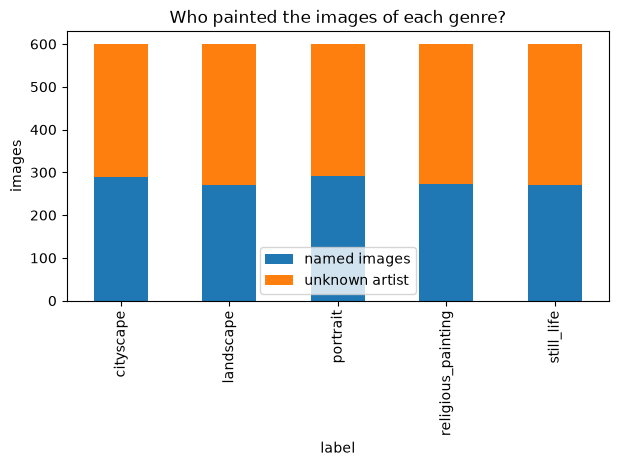

In [ ]:
table[["named images", "unknown artist"]].plot(kind="bar", stacked=True, figsize=(7, 3.5), title="Who painted the images of each genre?")
plt.ylabel("images")
plt.show()

## 4. Could the artist or the style give away the genre?

The network only sees pixels, but pixels carry a painter's habits. If knowing the painter (or the style) already tells
the genre, a network could score well by recognising the painter instead of the genre. This is the reason for the
museum A / museum B split of ADR 0003.

We measure it without any neural network: to guess the genre of one painting, we look at all the *other* paintings with
the same artist (or style) and take their most frequent genre.

In [9]:
def guess_genre_from(column, data):
    """Share of paintings whose genre is guessed right from the other paintings with the same `column` value."""
    counts = data.groupby([column, "label"]).size().unstack(fill_value=0)  # one row per artist (or style), one column per genre
    right = 0
    total = 0
    for _, painting in data.iterrows():
        others = counts.loc[painting[column]].copy()
        others[painting["label"]] -= 1  # leave this painting out
        if others.sum() == 0:
            continue  # it is alone in its group, nothing to guess from
        right += others.idxmax() == painting["label"]
        total += 1
    return right / total, total


acc_artist, n_artist = guess_genre_from("artist", known)
acc_style, n_style = guess_genre_from("style", meta)
print(f"knowing only the artist ({n_artist} paintings with a named artist): {acc_artist:.1%} right")
print(f"knowing only the style  ({n_style} paintings): {acc_style:.1%} right")
print(f"guessing at random: {1 / len(genres):.0%}")

knowing only the artist (1391 paintings with a named artist): 70.2% right
knowing only the style  (3000 paintings): 48.6% right
guessing at random: 20%


## 5. Which styles fill each genre?

In [10]:
for genre, group in meta.groupby("label"):
    print(f"{genre:19s}", group["style"].value_counts().head(3).to_dict())

cityscape           {'Post_Impressionism': 133, 'Impressionism': 129, 'Romanticism': 61}
landscape           {'Impressionism': 170, 'Realism': 154, 'Post_Impressionism': 68}
portrait            {'Romanticism': 94, 'Expressionism': 83, 'Realism': 77}
religious_painting  {'Early_Renaissance': 128, 'Baroque': 101, 'Northern_Renaissance': 96}
still_life          {'Post_Impressionism': 102, 'Cubism': 88, 'Impressionism': 81}


## 6. Size of the paintings and the centre crop

The download script cut a centred square out of each painting. For a very wide or very tall painting, this throws part
of it away.

     orig_width  orig_height
min      1381.0       1381.0
50%      1412.0       1382.0
max      4973.0       4521.0 

wider than 1.5:1: 323 | taller than 1.5:1: 279
area kept by the centre crop: median 75%, worst case 28%


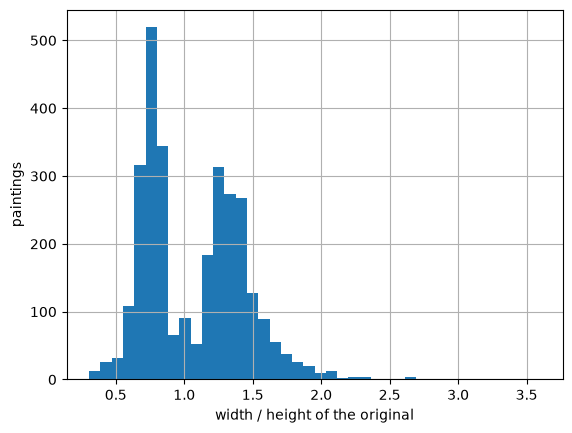

In [11]:
sides = meta[["orig_width", "orig_height"]]
print(sides.describe().loc[["min", "50%", "max"]], "\n")

ratio = meta["orig_width"] / meta["orig_height"]
print("wider than 1.5:1:", (ratio > 1.5).sum(), "| taller than 1.5:1:", (ratio < 1 / 1.5).sum())

kept = sides.min(axis=1) / sides.max(axis=1)  # share of the area kept by the centre crop
print(f"area kept by the centre crop: median {kept.median():.0%}, worst case {kept.min():.0%}")

ratio.hist(bins=40)
plt.xlabel("width / height of the original")
plt.ylabel("paintings")
plt.show()

## 7. Duplicates and file format

If the same image were in two files, it could land in train and in test. We compare the bytes of the files.

In [12]:
hashes = meta["path"].map(lambda p: hashlib.sha1((DATA_DIR / p).read_bytes()).hexdigest())
print("paintings whose file is identical to another one:", hashes.duplicated(keep=False).sum())

formats = set()
for p in meta["path"]:
    with Image.open(DATA_DIR / p) as im:
        formats.add((im.size, im.mode, im.format))
print("sizes / modes / formats found:", formats)

paintings whose file is identical to another one: 0
sizes / modes / formats found: {((224, 224), 'RGB', 'JPEG')}


## 8. A look at the paintings

Six random paintings per genre. **Licence:** WikiArt images must not be committed or published, so the output of the next
cell is cleared before this notebook goes into Git.

In [ ]:
fig, axes = plt.subplots(len(genres), 6, figsize=(12, 10))
for row, genre in enumerate(genres):
    sample = meta[meta["label"] == genre].sample(6, random_state=0)
    for col, path in enumerate(sample["path"]):
        axes[row, col].imshow(Image.open(DATA_DIR / path))
        axes[row, col].axis("off")
    axes[row, 0].set_title(genre, loc="left")
plt.show()

## What we learned

- The download is complete: 3,000 files, 600 per genre, nothing missing, nothing stale.
- 54% of the paintings (1,607) have `Unknown Artist`. The other 1,393 come from 102 named artists, and 82 of them painted
  in more than one genre.
- Knowing only the artist gives the right genre for about 70% of the named-artist paintings, and knowing only the style
  for about 49% of all paintings, against 20% by chance. So a network could take shortcuts: ADR 0003 holds out whole
  artists for the test set.
- The centre crop keeps a median 75% of a painting, and only 28% in the worst case. About one painting in five is wider
  or taller than 1.5:1.
- No file is duplicated, and every image is a 224 x 224 RGB JPEG.